# Portifolio_2Bimestre_2 — Segmentação

Comparação entre segmentação semântica e por instância para moedas e outra imagem do skimage.

In [1]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from scipy import ndimage as ndi
from skimage import data, feature, filters, morphology, segmentation, util
from IPython.display import display

PASTA = Path("plots_segmentacao")
PASTA.mkdir(exist_ok=True)

def segmentar(imagem, distancia_minima=10, ajuste_limiar=0,
              fechamento=0, area_minima=0, limpar_borda=False):
    imagem = util.img_as_ubyte(imagem)
    suave = filters.gaussian(imagem, sigma=1, preserve_range=True)
    mascara = suave > filters.threshold_otsu(suave) + ajuste_limiar

    if fechamento:
        mascara = morphology.closing(mascara, footprint=morphology.disk(fechamento))
    mascara = ndi.binary_fill_holes(mascara)

    if area_minima:
        mascara = morphology.remove_small_objects(mascara, max_size=area_minima - 1)
    if limpar_borda:
        mascara = segmentation.clear_border(mascara)

    distancia = ndi.distance_transform_edt(mascara)
    picos = feature.peak_local_max(
        distancia, min_distance=distancia_minima,
        labels=mascara, exclude_border=False
    )
    marcadores = np.zeros(mascara.shape, dtype=int)
    marcadores[tuple(picos.T)] = np.arange(1, len(picos) + 1)
    rotulos = segmentation.watershed(-distancia, marcadores, mask=mascara)
    return imagem, mascara, rotulos


def plotar(imagem, mascara, rotulos, objeto, arquivo):
    cores = plt.get_cmap("hsv")(np.linspace(0, 1, rotulos.max() + 1))[:, :3]
    cores[0] = 0
    colorida = cores[rotulos]

    fig, eixos = plt.subplots(1, 3, figsize=(15, 4.8))
    eixos[0].imshow(imagem, cmap="gray")
    eixos[1].imshow(mascara, cmap="gray", vmin=0, vmax=1)
    eixos[2].imshow(colorida)
    titulos = ["Entrada", "Semântica (1 classe: " + objeto + ")",
               "Instância (1 cor por " + objeto + ")"]
    for eixo, titulo in zip(eixos, titulos):
        eixo.set_title(titulo)
        eixo.axis("off")
    fig.tight_layout()
    fig.savefig(arquivo, dpi=200, bbox_inches="tight")
    display(fig)
    plt.close(fig)


## 1. Moedas — skimage.data.coins

Instâncias: 24


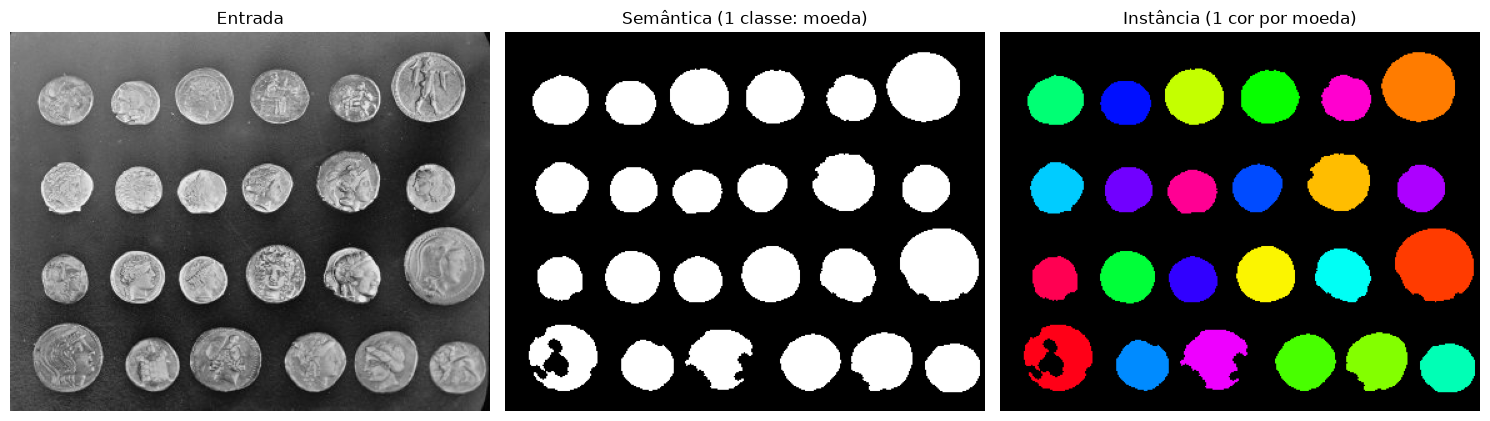

In [2]:
entrada = data.coins()
imagem, mascara, rotulos = segmentar(
    entrada, distancia_minima=29, ajuste_limiar=25,
    fechamento=3, area_minima=300, limpar_borda=True
)
print("Instâncias:", rotulos.max())
plotar(imagem, mascara, rotulos, "moeda", PASTA / "comparacao_coins.png")

## 2. Outra imagem — skimage.data.binary_blobs

Instâncias: 30


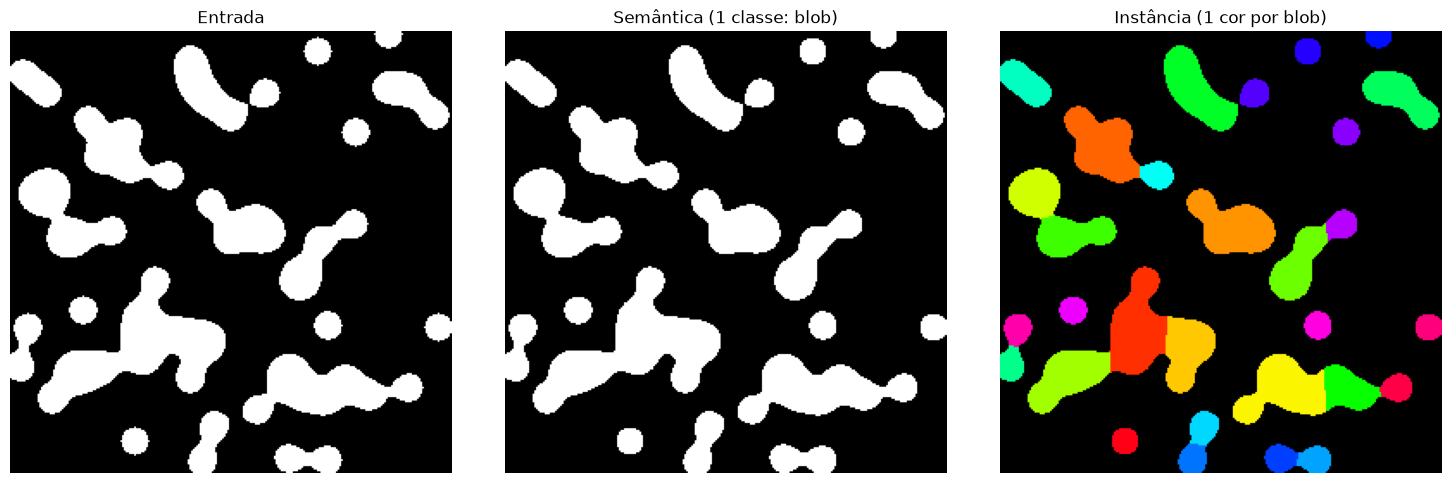

In [3]:
entrada = data.binary_blobs(
    length=256, blob_size_fraction=0.12, volume_fraction=0.25, rng=42
)
imagem, mascara, rotulos = segmentar(
    entrada, distancia_minima=18, area_minima=30
)
print("Instâncias:", rotulos.max())
plotar(imagem, mascara, rotulos, "blob", PASTA / "comparacao_binary_blobs.png")

## Análise

Foram encontrados 24 rótulos nas moedas e 30 nos blobs. A textura das moedas dificulta o limiar; os blobs têm contraste mais limpo, mas formas irregulares ou encostadas podem ser divididas pelo watershed. A semântica mantém uma classe; a instância colore cada região separadamente.